<div style="padding: 28px 32px; border: 1px solid #bfdbfe; border-left: 8px solid #2563eb; border-radius: 12px; background: linear-gradient(135deg, #eff6ff 0%, #f8fafc 100%);">

<h1 style="margin: 0; color: #1e3a8a;">Machine Learning Zoomcamp 2026</h1>
<p style="margin: 8px 0 18px; font-size: 1.2em; color: #334155;"><strong>Homework 3</strong> · Classification</p>

| Student | Cohort | Dataset | Environment |
| :--- | :--- | :--- | :--- |
| Carlos Ibarra | 2026 | 2026 Course Lead Scoring | Python 3.11+ · Pandas · Scikit-Learn |

</div>

### Learning path

| Step | Focus |
| :---: | :--- |
| 01 | Initial setup and data loading |
| 02 | Missing-value preparation |
| 03 | Q1: Most frequent industry (Mode) |
| 04 | Q2: Numerical feature correlations |
| 05 | Train, validation, and test split |
| 06 | Q3: Mutual information analysis |
| 07 | Q4: Logistic regression baseline |
| 08 | Q5: Feature elimination |
| 09 | Q6: Regularization parameter tuning |
| 10 | Results dashboard and summary |


<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 1 · Initial setup and data loading

**Objective.** Import required libraries, configure reproducible execution parameters, and load the 2026 lead scoring dataset into a Pandas DataFrame.

</div>


In [1]:
# Import pathlib for filesystem path resolution.
from pathlib import Path

# Import NumPy for numerical operations.
import numpy as np
# Import Pandas for tabular data manipulation.
import pandas as pd
# Import Matplotlib for creating visualizations.
import matplotlib.pyplot as plt
# Import Seaborn for statistical visualizations.
import seaborn as sns

# Import Scikit-Learn components for modeling and metrics.
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mutual_info_score

# Apply Seaborn's whitegrid theme for consistent visual formatting.
sns.set_theme(style="whitegrid")

# Define reproducible constants.
DATA_PATH = Path("data/course_lead_scoring_2026.csv")
TARGET = "converted"
RANDOM_STATE = 42

MODEL_PARAMS = {
    "solver": "liblinear",
    "C": 1.0,
    "max_iter": 1000,
    "random_state": RANDOM_STATE,
}
C_VALUES = [0.000001, 0.00001, 0.0001, 0.001]

# Load dataset.
df = pd.read_csv(DATA_PATH)

# Display dataset dimensions and initial sample.
print(f"Shape: {df.shape}")
df.head()


Shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


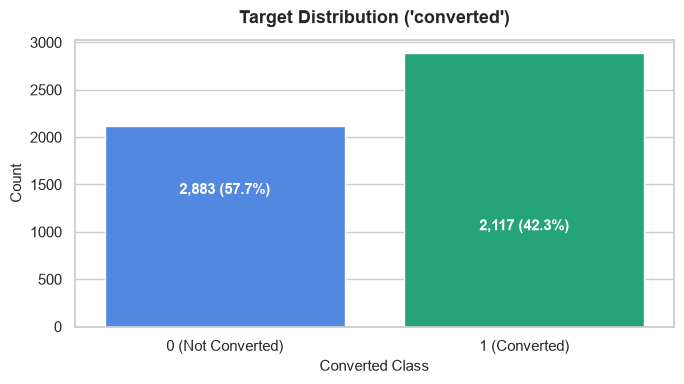

In [2]:
# Select target variable and compute distribution.
target_counts = df[TARGET].value_counts(dropna=False)
target_proportions = df[TARGET].value_counts(normalize=True)

# Create a figure for target class balance.
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=target_counts.index, y=target_counts.values, hue=target_counts.index, palette=["#3b82f6", "#10b981"], legend=False, ax=ax)
ax.set_title("Target Distribution ('converted')", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Converted Class", fontsize=11)
ax.set_ylabel("Count", fontsize=11)
ax.set_xticks([0, 1], ["0 (Not Converted)", "1 (Converted)"])

for i, count in enumerate(target_counts):
    prop = target_proportions.iloc[i] * 100
    ax.annotate(f"{count:,} ({prop:.1f}%)", (i, count / 2), ha="center", va="center", color="white", fontweight="bold", fontsize=11)

plt.tight_layout()
plt.show()


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Target distribution**
The dataset contains **`5,000`** observations and **`9`** columns. The target variable `converted` has no missing values and comprises **`2,883`** positive outcomes (**`57.7%`**) and **`2,117`** negative outcomes (**`42.3%`**).

</div>


<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 2 · Missing-value preparation

**Objective.** Identify predictor data types and apply the prescribed missing-value treatment: fill categorical features with `'NA'` and numerical features with `0.0`.

</div>


In [3]:
# Identify categorical and numerical predictor columns excluding TARGET.
categorical_features = list(df.select_dtypes(include=["object", "string"]).columns)
categorical_features = [col for col in categorical_features if col != TARGET]

numerical_features = list(df.select_dtypes(include=["number"]).columns)
numerical_features = [col for col in numerical_features if col != TARGET]

# Count missing values before imputation.
missing_before = df[categorical_features + numerical_features].isnull().sum()
missing_before = missing_before[missing_before > 0].sort_values(ascending=False)
print("Missing values before imputation:")
print(missing_before)

# Apply prescribed missing-value replacement.
df[categorical_features] = df[categorical_features].fillna("NA")
df[numerical_features] = df[numerical_features].fillna(0.0)

# Confirm no missing values remain in features or target.
assert df.isnull().sum().sum() == 0, "Missing values remain after preparation."
print("\nAll missing values successfully imputed.")


Missing values before imputation:
annual_income        369
industry             240
location             208
employment_status    194
lead_source          148
lead_score            35
dtype: int64

All missing values successfully imputed.


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Missing values**
Missing values were resolved across 6 features: **`4`** categorical columns (`lead_source`, `industry`, `employment_status`, `location`) filled with `'NA'` and **`2`** numerical columns (`annual_income`, `lead_score`) filled with `0.0`. Zero missing values remain.

</div>


<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Q1 · Most frequent industry

**Question.** What is the most frequent observation (mode) for the column `industry`?

</div>


In [4]:
# Count occurrences for each industry category.
industry_counts = df["industry"].value_counts(dropna=False)
industry_mode = df["industry"].mode()[0]
mode_count = industry_counts.loc[industry_mode]

print("Industry frequency counts:")
print(industry_counts)
print(f"\nMode of industry: '{industry_mode}' ({mode_count} records)")


Industry frequency counts:
industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

Mode of industry: 'technology' (1173 records)


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Q1**
The most frequent observation (mode) for `industry` is **`technology`** with **`1,173`** occurrences (**`23.5%`** of total records).

</div>


<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Q2 · Numerical feature correlations

**Question.** What are the two features that have the biggest correlation among the candidate pairs?

</div>


In [5]:
# Compute Pearson correlation matrix for numerical features.
corr_matrix = df[numerical_features].corr()

# Define the candidate pairs specified in the assignment.
candidate_pairs = [
    ("interaction_count", "lead_score"),
    ("number_of_courses_viewed", "lead_score"),
    ("number_of_courses_viewed", "interaction_count"),
    ("annual_income", "interaction_count"),
]

# Evaluate correlation values for each candidate pair.
pair_records = []
for f1, f2 in candidate_pairs:
    corr_val = corr_matrix.loc[f1, f2]
    pair_records.append({"pair": f"{f1} and {f2}", "correlation": corr_val})

pair_df = pd.DataFrame(pair_records).sort_values(by="correlation", ascending=False).reset_index(drop=True)
print("Candidate pair correlations (sorted):")
print(pair_df)

top_pair = pair_df.iloc[0]
print(f"\nHighest correlation pair: '{top_pair['pair']}' ({top_pair['correlation']:.4f})")


Candidate pair correlations (sorted):
                                             pair  correlation
0                interaction_count and lead_score     0.915746
1         number_of_courses_viewed and lead_score     0.757204
2  number_of_courses_viewed and interaction_count     0.721609
3             annual_income and interaction_count     0.122842

Highest correlation pair: 'interaction_count and lead_score' (0.9157)


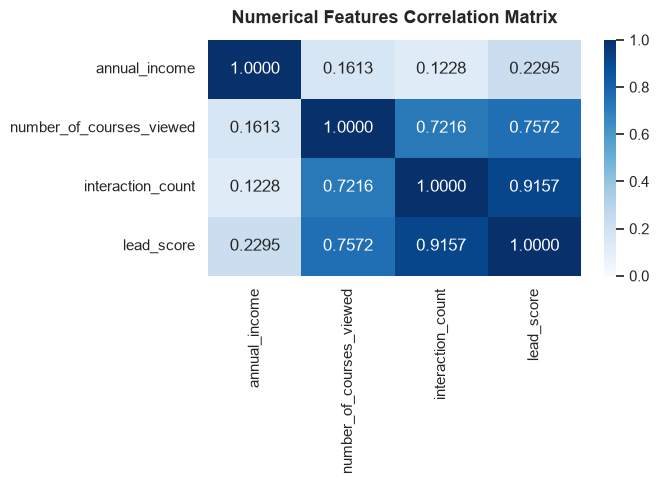

In [6]:
# Visualize numerical correlation heatmap.
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".4f", cmap="Blues", vmin=0, vmax=1, cbar=True)
plt.title("Numerical Features Correlation Matrix", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Q2**
The feature pair with the highest correlation is **`interaction_count and lead_score`** with a Pearson correlation of **`0.9157`**.

</div>


<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 4 · Train, validation, and test split

**Objective.** Split the dataset into 60% training, 20% validation, and 20% test subsets using the prescribed two-stage `train_test_split` calls, extract targets, and remove `converted` from predictor frames.

</div>


In [7]:
# Split full dataset into 80% train+val and 20% test.
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)

# Split 80% train+val into 60% train and 20% validation.
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=RANDOM_STATE)

# Reset indices for clean positional indexing.
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Extract target arrays.
y_train = df_train[TARGET].values
y_val = df_val[TARGET].values
y_test = df_test[TARGET].values

# Remove target column from predictor DataFrames.
del df_train[TARGET]
del df_val[TARGET]
del df_test[TARGET]

# Verify partition dimensions.
print(f"Train subset: {len(df_train):,} rows ({len(df_train)/len(df):.0%})")
print(f"Validation subset: {len(df_val):,} rows ({len(df_val)/len(df):.0%})")
print(f"Test subset: {len(df_test):,} rows ({len(df_test)/len(df):.0%})")
print(f"Target absent from predictor frames: {TARGET not in df_train.columns}")


Train subset: 3,000 rows (60%)
Validation subset: 1,000 rows (20%)
Test subset: 1,000 rows (20%)
Target absent from predictor frames: True


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Data Splitting**
The dataset was partitioned into **`3,000`** train (60%), **`1,000`** validation (20%), and **`1,000`** test (20%) rows. The target variable was isolated from all predictor matrices.

</div>


<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Q3 · Mutual information

**Question.** Which categorical variable has the biggest mutual information score with `converted` on the training set?

</div>


In [8]:
# Compute mutual information score for each categorical feature on training data.
mi_results = []
for feature in categorical_features:
    score = mutual_info_score(df_train[feature], y_train)
    mi_results.append({
        "feature": feature,
        "mutual_info_raw": score,
        "mutual_info_rounded": round(score, 2),
    })

mi_df = pd.DataFrame(mi_results).sort_values(by="mutual_info_raw", ascending=False).reset_index(drop=True)
print("Mutual information scores with target (converted):")
print(mi_df)

top_mi = mi_df.iloc[0]
print(f"\nHighest mutual information feature: '{top_mi['feature']}' ({top_mi['mutual_info_rounded']})")


Mutual information scores with target (converted):
             feature  mutual_info_raw  mutual_info_rounded
0        lead_source         0.034346                 0.03
1  employment_status         0.018966                 0.02
2           industry         0.001995                 0.00
3           location         0.001043                 0.00

Highest mutual information feature: 'lead_source' (0.03)


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Q3**
The categorical feature with the highest mutual information score is **`lead_source`** with a score of **`0.0343`**, rounding to **`0.03`**.

</div>


<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Q4 · Logistic regression baseline

**Question.** What validation accuracy does a logistic regression model achieve after one-hot encoding all features?

</div>


In [9]:
# Convert predictor DataFrames to record dictionaries.
train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

# Fit DictVectorizer on training records and transform train and validation sets.
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Fit Logistic Regression model with prescribed reproducibility parameters.
model = LogisticRegression(**MODEL_PARAMS)
model.fit(X_train, y_train)

# Predict validation outcomes and compute accuracy.
y_pred_val = model.predict(X_val)
original_accuracy = accuracy_score(y_val, y_pred_val)
rounded_accuracy = round(original_accuracy, 2)

print(f"Encoded feature count: {X_train.shape[1]}")
print(f"Validation accuracy (unrounded): {original_accuracy:.6f}")
print(f"Validation accuracy (rounded to 2 decimals): {rounded_accuracy}")


Encoded feature count: 28
Validation accuracy (unrounded): 0.645000
Validation accuracy (rounded to 2 decimals): 0.65


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Q4**
The logistic regression baseline achieves a validation accuracy of **`0.6450`**, which rounds to **`0.65`**.

</div>


<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Q5 · Feature elimination

**Question.** Which feature has the smallest signed difference between original accuracy and subset accuracy?

</div>


In [10]:
# Evaluate the impact of eliminating each feature individually.
elimination_records = []
all_predictors = list(df_train.columns)

for feature in all_predictors:
    # Exclude the feature from training and validation sets.
    df_train_sub = df_train.drop(columns=[feature])
    df_val_sub = df_val.drop(columns=[feature])

    # Refit vectorizer and transform reduced data.
    dv_sub = DictVectorizer(sparse=False)
    X_train_sub = dv_sub.fit_transform(df_train_sub.to_dict(orient="records"))
    X_val_sub = dv_sub.transform(df_val_sub.to_dict(orient="records"))

    # Refit logistic regression model with identical hyperparameters.
    model_sub = LogisticRegression(**MODEL_PARAMS)
    model_sub.fit(X_train_sub, y_train)

    # Compute validation accuracy and signed difference.
    sub_acc = accuracy_score(y_val, model_sub.predict(X_val_sub))
    diff = original_accuracy - sub_acc

    elimination_records.append({
        "feature": feature,
        "subset_accuracy": sub_acc,
        "difference": diff,
    })

elim_df = pd.DataFrame(elimination_records).sort_values(by="difference", ascending=True).reset_index(drop=True)
print("All features elimination results (sorted by signed difference):")
print(elim_df)

# Filter for the candidates specified in the assignment.
q5_candidates = ["lead_source", "number_of_courses_viewed", "interaction_count"]
cand_df = elim_df[elim_df["feature"].isin(q5_candidates)].sort_values(by="difference", ascending=True).reset_index(drop=True)
print("\nTarget candidate comparison:")
print(cand_df)

top_q5 = cand_df.iloc[0]
print(f"\nCandidate with smallest signed difference: '{top_q5['feature']}' ({top_q5['difference']:.6f})")


All features elimination results (sorted by signed difference):
                    feature  subset_accuracy  difference
0             annual_income            0.724      -0.079
1                  industry            0.645       0.000
2         employment_status            0.645       0.000
3                  location            0.645       0.000
4                lead_score            0.644       0.001
5  number_of_courses_viewed            0.643       0.002
6               lead_source            0.642       0.003
7         interaction_count            0.601       0.044

Target candidate comparison:
                    feature  subset_accuracy  difference
0  number_of_courses_viewed            0.643       0.002
1               lead_source            0.642       0.003
2         interaction_count            0.601       0.044

Candidate with smallest signed difference: 'number_of_courses_viewed' (0.002000)


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Q5**
Among the target options, **`number_of_courses_viewed`** exhibits the smallest signed difference of **`0.0020`** (`0.6450 - 0.6430`), indicating the least performance drop when removed.

</div>


<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Q6 · Regularization parameter tuning

**Question.** Which value of parameter `C` leads to the best accuracy on the validation set?

</div>


In [11]:
# Evaluate regularization parameter C across candidate values.
c_eval_records = []

for c_val in C_VALUES:
    # Update hyperparameter C.
    params = MODEL_PARAMS.copy()
    params["C"] = c_val

    # Train regularized logistic regression model.
    model_c = LogisticRegression(**params)
    model_c.fit(X_train, y_train)

    # Measure validation accuracy and round to 3 decimals.
    val_acc = accuracy_score(y_val, model_c.predict(X_val))
    c_eval_records.append({
        "C": c_val,
        "accuracy_raw": val_acc,
        "accuracy_round3": round(val_acc, 3),
    })

c_df = pd.DataFrame(c_eval_records)
print("Regularization tuning results:")
print(c_df)

# Determine the best C value using maximum rounded accuracy.
best_score = c_df["accuracy_round3"].max()
best_candidates = c_df[c_df["accuracy_round3"] == best_score].sort_values(by="C", ascending=True)
best_c = best_candidates.iloc[0]["C"]

print(f"\nBest rounded validation accuracy: {best_score}")
print(f"Optimal parameter C: {best_c}")


Regularization tuning results:
          C  accuracy_raw  accuracy_round3
0  0.000001         0.598            0.598
1  0.000010         0.598            0.598
2  0.000100         0.613            0.613
3  0.001000         0.645            0.645

Best rounded validation accuracy: 0.645
Optimal parameter C: 0.001


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Q6**
The optimal regularization parameter is **`C = 0.001`**, achieving the highest validation accuracy of **`0.645`** (rounded to 3 decimals).

</div>


<div style="padding: 22px 26px; border: 1px solid #bfdbfe; border-top: 7px solid #2563eb; border-radius: 12px; background: #f8fafc;">

## Homework 3 · Results dashboard

| Question | Focus | Final answer |
| :---: | :--- | :--- |
| **Q1** | Most frequent industry | **`technology`** (`1,173` occurrences) |
| **Q2** | Highest numerical correlation | **`interaction_count and lead_score`** (`0.9157`) |
| **Q3** | Highest mutual information | **`lead_source`** (`0.03`) |
| **Q4** | Baseline validation accuracy | **`0.65`** (`0.6450`) |
| **Q5** | Smallest feature elimination difference | **`number_of_courses_viewed`** (`0.0020`) |
| **Q6** | Best regularization parameter | **`C = 0.001`** (`0.645` accuracy) |

</div>

<div style="margin-top: 16px; padding: 16px 20px; border-left: 5px solid #f59e0b; border-radius: 8px; background: #fffbeb;">

### Key takeaway

Predicting customer course conversion relies strongly on engagement signals: `interaction_count` and `lead_score` exhibit substantial collinearity (**`0.9157`**), and `lead_source` is the most informative categorical predictor (**`MI = 0.03`**). The one-hot encoded logistic regression baseline achieves **`65%`** validation accuracy, with `number_of_courses_viewed` showing the least individual impact upon removal (**`0.002`** difference). Evaluating regularized variants confirms that lighter penalty (**`C = 0.001`**) achieves the best predictive balance with **`0.645`** accuracy.

</div>
